# Red Wine Quality Classification (Draft Portfolio)

In this project I want to find out whether the physicochemical properties of red wine can be used to classify wines into two quality groups, "good" and "average".

## 1. Data selection

I used the red wine file from the Wine Quality dataset on the UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/186/wine+quality

The data was collected by Cortez et al. (2009) from Portuguese "Vinho Verde" wines and is licensed under CC BY 4.0. I only used the red wine file (`winequality-red.csv`) so I could focus on doing each step properly. It has 1599 rows and 12 columns: 11 measurements (for example acidity, sugar, pH and alcohol) and a quality score given by tasters. All the data is real. I did not make up or change any values.

In [1]:
import pandas as pd
df = pd.read_csv("winequality-red.csv", sep=";")
print(df.shape)
df.head()


(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Checking and cleaning the data

First I checked the data. There are no missing values in any column. There were 240 duplicated rows, so I removed them and kept 1359 rows. I did this because if the same wine ended up in both the training set and the test set, the model would be tested on something it had already seen and the score would look better than it really is. Two different wines could in theory have the same rounded measurements, so I can't be completely sure that all of them are real copies, but I treated identical rows as duplicates.

After cleaning, most wines have a quality of 5 (577 wines) or 6 (535 wines). There are 167 wines with quality 7, and only a few with 3 (10 wines), 4 (53 wines) or 8 (17 wines).

I decided that a wine is "good" if its quality is 6 or above and "average" if it is 5 or below. This is a rule I chose for this project, not an official UCI definition. It gives 719 good wines and 640 average wines, which is fairly balanced (about 53% good), so I kept this cut-off.

As a first look, the average alcohol of the good wines (10.89) is higher than the average alcohol of the average wines (9.92).

In [2]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["quality"].value_counts().sort_index())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
240
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


In [3]:
df_clean = df.drop_duplicates()
print(df_clean.shape)
print(df_clean["quality"].value_counts().sort_index())

(1359, 12)
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


In [4]:
df_clean = df.drop_duplicates().copy()
df_clean["good"] = (df_clean["quality"] >= 6).astype(int)
print(df_clean.shape)
print(df_clean["good"].value_counts())

(1359, 13)
good
1    719
0    640
Name: count, dtype: int64


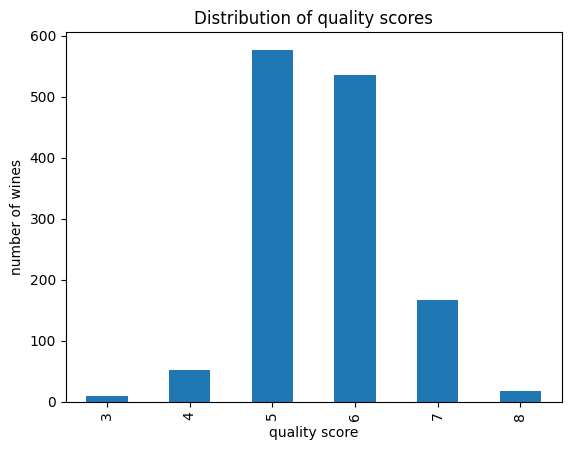

In [5]:
import matplotlib.pyplot as plt

df_clean["quality"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("quality score")
plt.ylabel("number of wines")
plt.title("Distribution of quality scores")
plt.show()

In [6]:
print(df_clean.groupby("good")["alcohol"].mean())

good
0     9.920781
1    10.887645
Name: alcohol, dtype: float64


## 3. Preparing the data for the model

I used the 11 measurements as the inputs (X) and the good/average label as the output (y). I left the `quality` column out of X, because the label is made from it and keeping it would give the model the answer.

I split the data into a training set (1087 wines) and a test set (272 wines), 80% and 20%. I used `stratify` so both sets have a similar share of good wines, and `random_state=42` so I can get the same split again.

Then I standardised the features with StandardScaler. The scaler learned from the training set only and was then applied to the test set, so nothing from the test set was used during training.

In [7]:
X = df_clean.drop(columns=["quality", "good"])
y = df_clean["good"]
print(X.shape)
print(y.shape)


(1359, 11)
(1359,)


In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(1087, 11) (272, 11)


In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(X_train_s.shape, X_test_s.shape)
print(X_train_s.mean(axis=0).round(2))

(1087, 11) (272, 11)
[ 0.  0.  0.  0.  0. -0. -0.  0. -0.  0. -0.]


## 4. Model training

I trained a Logistic Regression model on the training set. I set `max_iter=1000` to give it enough steps to finish learning.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)
pred = model.predict(X_test_s)
print(accuracy_score(y_test, pred))
print(y_test.mean())

0.7352941176470589
0.5294117647058824


## 5. Validation

On the test set the model got an accuracy of 0.735 (200 of 272 wines correct). If a model just guessed "good" every time it would get 0.529, because 144 of the 272 test wines are good. So the model has learned something, but 73.5% is not very high.

Confusion matrix (rows = real, columns = predicted):

| | predicted average | predicted good |
|---|---|---|
| real average | 95 | 33 |
| real good | 39 | 105 |

| class | precision | recall | F1 | wines |
|---|---|---|---|---|
| average (0) | 0.71 | 0.74 | 0.73 | 128 |
| good (1) | 0.76 | 0.73 | 0.74 | 144 |

The model made 33 mistakes where an average wine was predicted as good and 39 mistakes where a good wine was predicted as average. The two kinds of mistake are about the same size, so the model does not lean towards one class.

One test split could be lucky, so I also ran 5-fold cross-validation. The five scores were 0.695, 0.691, 0.772, 0.743 and 0.749, and the mean was 0.73. This is close to the test set result, so the 73% does not look like luck, but the score changes by a few percentage points depending on the split.

The model coefficients (after standardising) show which properties it used most. Alcohol is the largest (+0.99), followed by sulphates (+0.48). Total sulfur dioxide (-0.52) and volatile acidity (-0.48) push the prediction towards "average". These numbers only show how the model makes its predictions. They do not prove that changing one property would change the quality of a wine.

In [11]:
from sklearn.metrics import confusion_matrix, classification_report
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

[[ 95  33]
 [ 39 105]]
              precision    recall  f1-score   support

           0       0.71      0.74      0.73       128
           1       0.76      0.73      0.74       144

    accuracy                           0.74       272
   macro avg       0.73      0.74      0.73       272
weighted avg       0.74      0.74      0.74       272



In [12]:
coef = pd.Series(model.coef_[0], index=X.columns).sort_values()
print(coef.round(2))

total sulfur dioxide   -0.52
volatile acidity       -0.48
chlorides              -0.22
citric acid            -0.14
density                -0.08
pH                     -0.07
residual sugar          0.06
free sulfur dioxide     0.18
fixed acidity           0.20
sulphates               0.48
alcohol                 0.99
dtype: float64


In [13]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
scores = cross_val_score(pipe, X, y, cv=5)
print(scores.round(3))
print(scores.mean().round(3))

[0.695 0.691 0.772 0.743 0.749]
0.73


## 6. Conclusion

Using only the 11 physicochemical measurements, logistic regression classified red wines as good or average with about 73% accuracy (5-fold cross-validation mean 0.73), compared with 53% for always guessing "good". Alcohol was the most important property in the model, followed by sulphates, total sulfur dioxide and volatile acidity.

Limitations:

- I have only used one model so far.
- Quality is a score from human tasters, so it is partly subjective, and that limits how accurate any model can be.
- I only tried one cut-off (6 or above) for "good".
- I treated identical rows as duplicates, which may not be true for every row.
- The data is only Portuguese "Vinho Verde" red wine, so the results may not apply to other wines.

For the final portfolio I plan to add Naive Bayes, Decision Tree and Random Forest and compare them with logistic regression. I also plan to use Linear Regression to predict the quality score.